In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:.4f}'.format
np.set_printoptions(precision=4, floatmode='fixed')

U = ['-30', '-25', '-20', '-15', '-10', '-5']
n = len(U)
A_low = np.array([
    [1,   2,   3,   5,   7,   9],
    [1/2, 1,   2,   3,   5,   7],
    [1/3, 1/2, 1,   2,   3,   5],
    [1/5, 1/3, 1/2, 1,   2,   3],
    [1/7, 1/5, 1/3, 1/2, 1,   2],
    [1/9, 1/7, 1/5, 1/3, 1/2, 1],
])

# A_mid = np.array([
#     [1,   1/2, 1/3, 1/5, 1/3, 1/2],
#     [2,   1,   1/2, 1/3, 1/2, 1  ],
#     [3,   2,   1,   1/2, 2,   3  ],
#     [5,   3,   2,   1,   3,   5  ],
#     [3,   2,   1/2, 1/3, 1,   1/2],
#     [2,   1,   1/3, 1/5, 1/2, 1  ],
# ])
# A_mid = np.array([
#     [1,   1/5, 1/5, 1/5, 1/3, 1/2],
#     [5,   1,   1,   1,   2,   3  ],
#     [5,   1,   1,   1,   2,   3  ],
#     [5,   1,   1,   1,   2,   3  ],
#     [3,   1/2, 1/2, 1/2, 1,   2  ],
#     [2,   1/3, 1/3, 1/3, 1/2, 1  ],
# ])
A_mid = np.array([
    [1,   1/3, 1/7, 1/5, 1/3, 1/3],   
    [3,   1,   1/2, 1/2, 2,   2  ],   
    [7,   2,   1,   1,   3,   9  ],   
    [5,   2,   1,   1,   3,   7  ],  
    [3,   1/2, 1/3, 1/3, 1,   2  ],   
    [3,   1/2, 1/9, 1/7, 1/2, 1  ],      
])
A_high = np.array([
    [1,   1/2, 1/3, 1/5, 1/7, 1/9],
    [2,   1,   1/2, 1/3, 1/5, 1/7],
    [3,   2,   1,   1/2, 1/3, 1/5],
    [5,   3,   2,   1,   1/2, 1/3],
    [7,   5,   3,   2,   1,   1/2],
    [9,   7,   5,   3,   2,   1],
])

print("Матрица парных сравнений: низкая температура")
print(pd.DataFrame(A_low, index=U, columns=U))


print("Матрица парных сравнений: средняя температура")
print(pd.DataFrame(A_mid, index=U, columns=U))


print("Матрица парных сравнений: высокая температура")
print(pd.DataFrame(A_high, index=U, columns=U))

Матрица парных сравнений: низкая температура
       -30    -25    -20    -15    -10     -5
-30 1.0000 2.0000 3.0000 5.0000 7.0000 9.0000
-25 0.5000 1.0000 2.0000 3.0000 5.0000 7.0000
-20 0.3333 0.5000 1.0000 2.0000 3.0000 5.0000
-15 0.2000 0.3333 0.5000 1.0000 2.0000 3.0000
-10 0.1429 0.2000 0.3333 0.5000 1.0000 2.0000
-5  0.1111 0.1429 0.2000 0.3333 0.5000 1.0000
Матрица парных сравнений: средняя температура
       -30    -25    -20    -15    -10     -5
-30 1.0000 0.3333 0.1429 0.2000 0.3333 0.3333
-25 3.0000 1.0000 0.5000 0.5000 2.0000 2.0000
-20 7.0000 2.0000 1.0000 1.0000 3.0000 9.0000
-15 5.0000 2.0000 1.0000 1.0000 3.0000 7.0000
-10 3.0000 0.5000 0.3333 0.3333 1.0000 2.0000
-5  3.0000 0.5000 0.1111 0.1429 0.5000 1.0000
Матрица парных сравнений: высокая температура
       -30    -25    -20    -15    -10     -5
-30 1.0000 0.5000 0.3333 0.2000 0.1429 0.1111
-25 2.0000 1.0000 0.5000 0.3333 0.2000 0.1429
-20 3.0000 2.0000 1.0000 0.5000 0.3333 0.2000
-15 5.0000 3.0000 2.0000 1.0000 0.5

In [33]:
#Способ 1 определения ФП НМ Стрепень нпринадлежности по формуде 1.10
def membership_formula(A):
    mu = 1 / np.sum(A, axis=0)     # субнормальное НМ
    mu_n = mu / max(mu)            # нормальное НМ
    return mu, mu_n

mu_low,  mu_low_n  = membership_formula(A_low)
mu_mid,  mu_mid_n  = membership_formula(A_mid)
mu_high, mu_high_n = membership_formula(A_high)

print("Низкая температура субнормальное НМ:")
print(pd.DataFrame(mu_low.reshape(1, -1), columns=U, index=['μ']))
print("Низкая температура нормальное НМ:")
print(pd.DataFrame(mu_low_n.reshape(1, -1), columns=U, index=['μ']))
print("\n")
print("Средняя температура субнормальное НМ:")
print(pd.DataFrame(mu_mid.reshape(1, -1), columns=U, index=['μ']))
print("Средняя температура нормальное НМ:")
print(pd.DataFrame(mu_mid_n.reshape(1, -1), columns=U, index=['μ']))
print("\n")
print("Высокая температура субнормальное НМ:")
print(pd.DataFrame(mu_high.reshape(1, -1), columns=U, index=['μ']))
print("Высокая температура нормальное НМ:")
print(pd.DataFrame(mu_high_n.reshape(1, -1), columns=U, index=['μ']))

Низкая температура субнормальное НМ:
     -30    -25    -20    -15    -10     -5
μ 0.4372 0.2395 0.1422 0.0845 0.0541 0.0370
Низкая температура нормальное НМ:
     -30    -25    -20    -15    -10     -5
μ 1.0000 0.5477 0.3252 0.1933 0.1236 0.0847


Средняя температура субнормальное НМ:
     -30    -25    -20    -15    -10     -5
μ 0.0455 0.1579 0.3239 0.3148 0.1017 0.0469
Средняя температура нормальное НМ:
     -30    -25    -20    -15    -10     -5
μ 0.1403 0.4875 1.0000 0.9720 0.3140 0.1447


Высокая температура субнормальное НМ:
     -30    -25    -20    -15    -10     -5
μ 0.0370 0.0541 0.0845 0.1422 0.2395 0.4372
Высокая температура нормальное НМ:
     -30    -25    -20    -15    -10     -5
μ 0.0847 0.1236 0.1933 0.3252 0.5477 1.0000


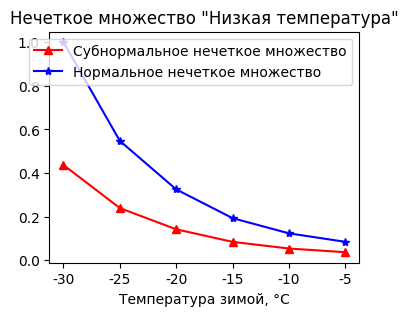

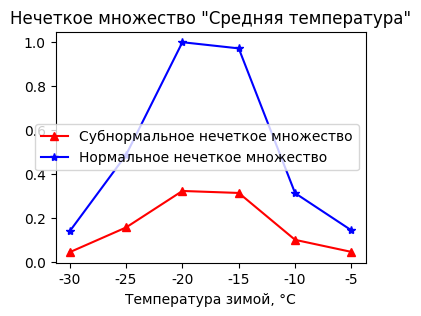

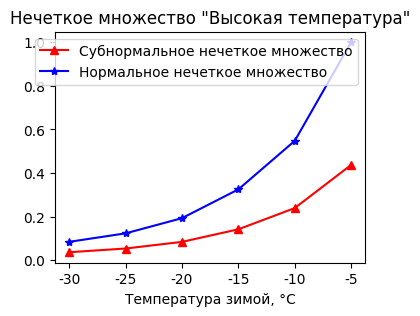

In [34]:
#Построение полоученного субнормального и нормаьного множества
plt.figure(figsize=(4, 3))
plt.plot(U, mu_low, '^-r', label='Субнормальное нечеткое множество')
plt.plot(U, mu_low_n, '*-b', label='Нормальное нечеткое множество')
plt.xlabel('Температура зимой, °C')
plt.title('Нечеткое множество "Низкая температура"')
plt.legend()
plt.show()

plt.figure(figsize=(4, 3))
plt.plot(U, mu_mid, '^-r', label='Субнормальное нечеткое множество')
plt.plot(U, mu_mid_n, '*-b', label='Нормальное нечеткое множество')
plt.xlabel('Температура зимой, °C')
plt.title('Нечеткое множество "Средняя температура"')
plt.legend()
plt.show()

plt.figure(figsize=(4, 3))
plt.plot(U, mu_high, '^-r', label='Субнормальное нечеткое множество')
plt.plot(U, mu_high_n, '*-b', label='Нормальное нечеткое множество')
plt.xlabel('Температура зимой, °C')
plt.title('Нечеткое множество "Высокая температура"')
plt.legend()
plt.show()


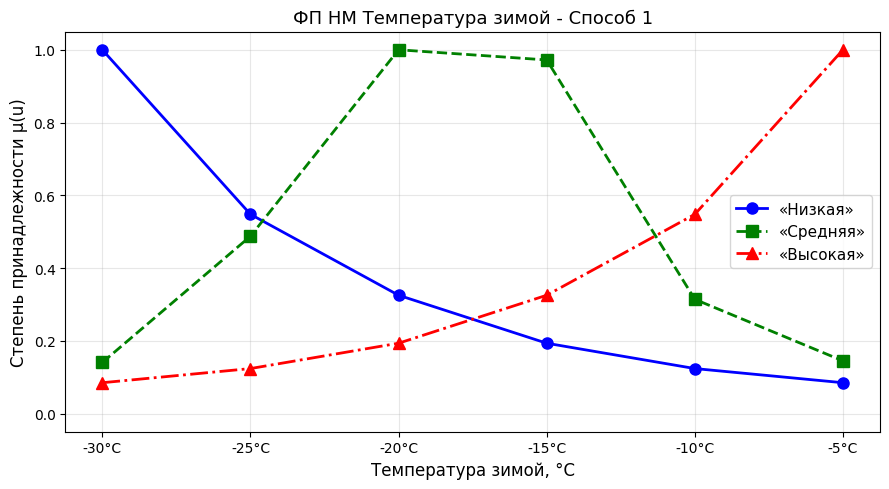

In [35]:
x = np.arange(len(U))

plt.figure(figsize=(9, 5))
plt.plot(x, mu_low_n,  'o-',  color='blue',  label='«Низкая»',  linewidth=2, markersize=8)
plt.plot(x, mu_mid_n,  's--', color='green', label='«Средняя»', linewidth=2, markersize=8)
plt.plot(x, mu_high_n, '^-.', color='red',   label='«Высокая»', linewidth=2, markersize=8)

plt.xticks(x, [f'{u}°C' for u in U])
plt.xlabel('Температура зимой, °C', fontsize=12)
plt.ylabel('Степень принадлежности μ(u)', fontsize=12)
plt.title('ФП НМ Температура зимой - Способ 1', fontsize=13)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

In [36]:
#Способ 2 Степень принадлежности через собственный вектор матрицы A
def membership_eig(A):
    values, vectors = np.linalg.eig(A)
    j_max = values.argmax()
    w = np.real(vectors[:, j_max])
    w = w / sum(w)
    mu = np.array(w, dtype=float)
    mu_n = mu / max(mu)
    incons = abs(max(values.real) - len(A))
    return mu, mu_n, incons

mu_low2,  mu_low2_n,  inc_low  = membership_eig(A_low)
mu_mid2,  mu_mid2_n,  inc_mid  = membership_eig(A_mid)
mu_high2, mu_high2_n, inc_high = membership_eig(A_high)

print("Низкая температура субнормальное НМ:")
print(pd.DataFrame(mu_low2.reshape(1, -1), columns=U, index=['μ']))
print("Низкая температура  нормальное НМ:")
print(pd.DataFrame(mu_low2_n.reshape(1, -1), columns=U, index=['μ']))
print(f"Мера несогласованности = {inc_low:.4f}")
print("\n")
print("Средняя температура субнормальное НМ:")
print(pd.DataFrame(mu_mid2.reshape(1, -1), columns=U, index=['μ']))
print("Средняя температура нормальное НМ:")
print(pd.DataFrame(mu_mid2_n.reshape(1, -1), columns=U, index=['μ']))
print(f"Мера несогласованности = {inc_mid:.4f}")
print("\n")
print("Высокая температура субнормальное НМ:")
print(pd.DataFrame(mu_high2.reshape(1, -1), columns=U, index=['μ']))
print("Высокая температура нормальное НМ:")
print(pd.DataFrame(mu_high2_n.reshape(1, -1), columns=U, index=['μ']))
print(f"Мера несогласованности = {inc_high:.4f}")

Низкая температура субнормальное НМ:
     -30    -25    -20    -15    -10     -5
μ 0.4148 0.2547 0.1532 0.0896 0.0540 0.0336
Низкая температура  нормальное НМ:
     -30    -25    -20    -15    -10     -5
μ 1.0000 0.6140 0.3694 0.2161 0.1303 0.0810
Мера несогласованности = 0.0580


Средняя температура субнормальное НМ:
     -30    -25    -20    -15    -10     -5
μ 0.0411 0.1489 0.3386 0.3051 0.1031 0.0632
Средняя температура нормальное НМ:
     -30    -25    -20    -15    -10     -5
μ 0.1213 0.4397 1.0000 0.9010 0.3045 0.1868
Мера несогласованности = 0.2238


Высокая температура субнормальное НМ:
     -30    -25    -20    -15    -10     -5
μ 0.0336 0.0540 0.0896 0.1532 0.2547 0.4148
Высокая температура нормальное НМ:
     -30    -25    -20    -15    -10     -5
μ 0.0810 0.1303 0.2161 0.3694 0.6140 1.0000
Мера несогласованности = 0.0580


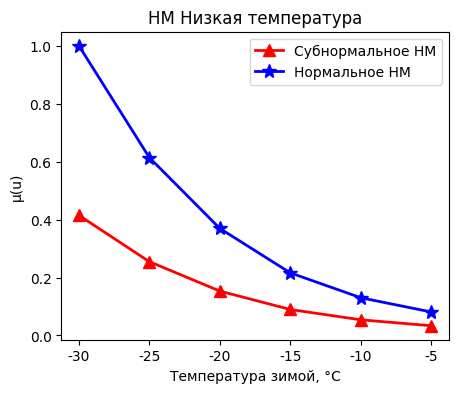

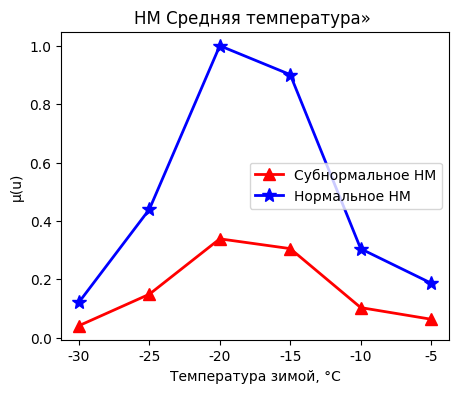

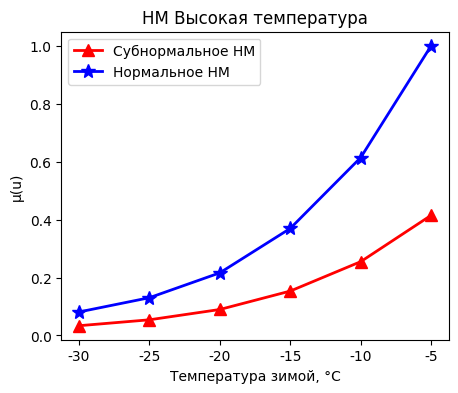

In [37]:
plt.figure(figsize=(5, 4))
plt.plot(U, mu_low2,   '^-r', label='Субнормальное НМ', linewidth=2, markersize=8)
plt.plot(U, mu_low2_n, '*-b', label='Нормальное НМ',    linewidth=2, markersize=10)
plt.xlabel('Температура зимой, °C')
plt.ylabel('μ(u)')
plt.title('НМ Низкая температура')
plt.legend()
plt.show()

plt.figure(figsize=(5, 4))
plt.plot(U, mu_mid2,   '^-r', label='Субнормальное НМ', linewidth=2, markersize=8)
plt.plot(U, mu_mid2_n, '*-b', label='Нормальное НМ',    linewidth=2, markersize=10)
plt.xlabel('Температура зимой, °C')
plt.ylabel('μ(u)')
plt.title('НМ Средняя температура» ')
plt.legend()
plt.show()

plt.figure(figsize=(5, 4))
plt.plot(U, mu_high2,   '^-r', label='Субнормальное НМ', linewidth=2, markersize=8)
plt.plot(U, mu_high2_n, '*-b', label='Нормальное НМ',    linewidth=2, markersize=10)
plt.xlabel('Температура зимой, °C')
plt.ylabel('μ(u)')
plt.title('НМ Высокая температура')
plt.legend()
plt.show()

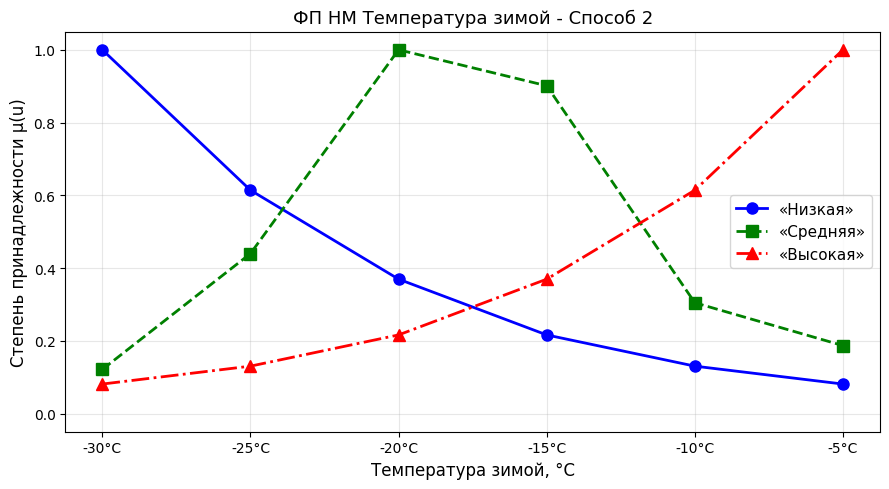

In [39]:
plt.figure(figsize=(9, 5))
plt.plot(x, mu_low2_n,  'o-',  color='blue',  label='«Низкая»',  linewidth=2, markersize=8)
plt.plot(x, mu_mid2_n,  's--', color='green', label='«Средняя»', linewidth=2, markersize=8)
plt.plot(x, mu_high2_n, '^-.', color='red',   label='«Высокая»', linewidth=2, markersize=8)
plt.xticks(x, [f'{u}°C' for u in U])
plt.xlabel("Температура зимой, °C", fontsize=12)
plt.ylabel("Степень принадлежности μ(u)", fontsize=12)
plt.title("ФП НМ Температура зимой - Способ 2", fontsize=13)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()


Мера несогласованности:
  высокая: 0.0735
  средняя: 0.1985
  низкая:  0.0735


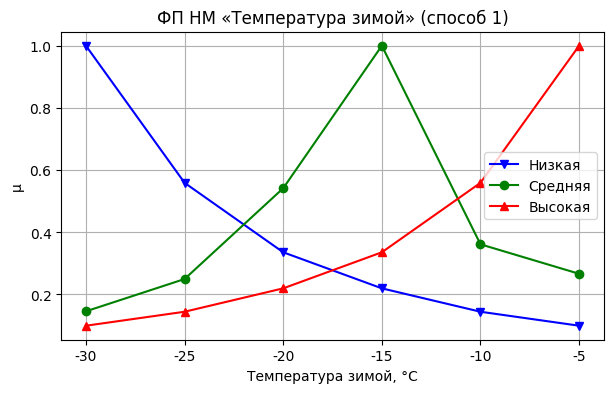

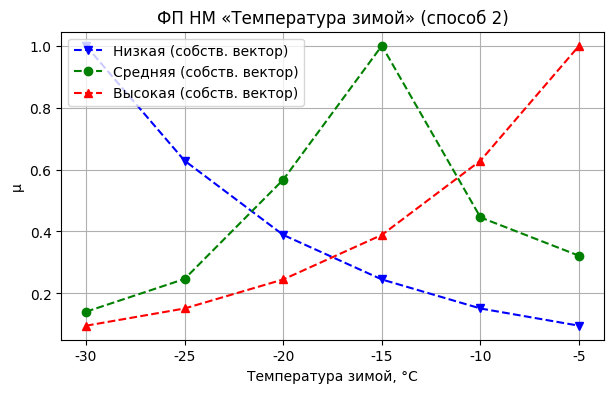

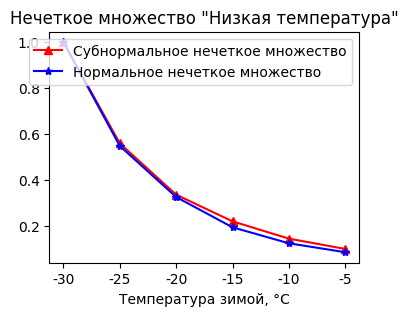

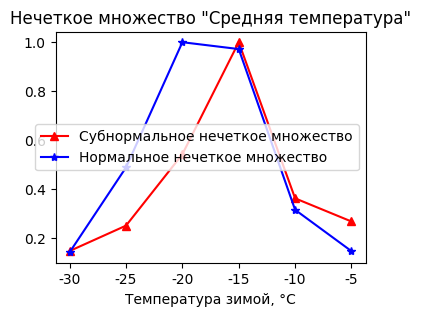

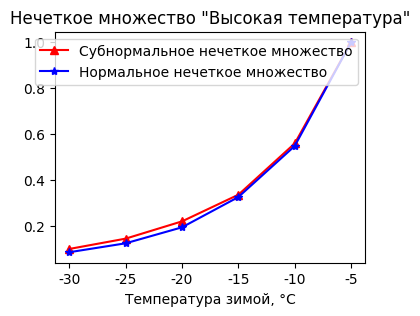

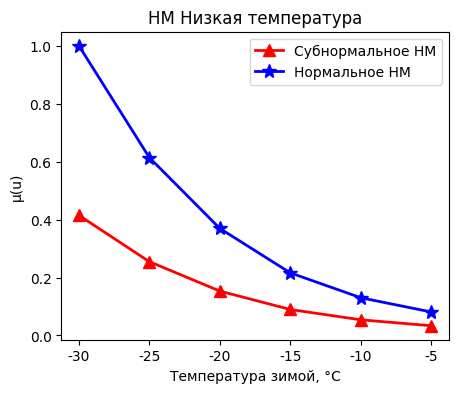

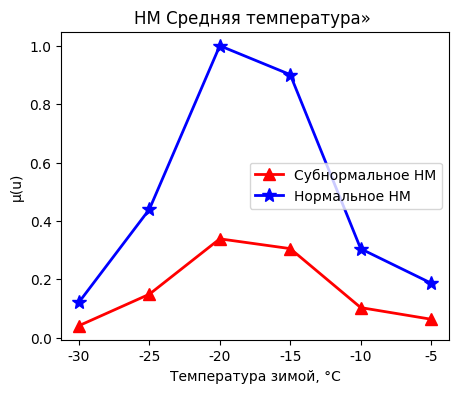

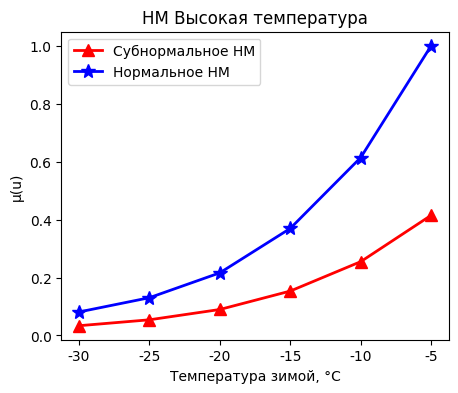

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
pd.options.display.float_format = '{:.4f}'.format
np.set_printoptions(precision=4, floatmode='fixed')

U = ['-30', '-25', '-20', '-15', '-10', '-5']

# === Терм «высокая» ===
A_high = np.array([
    [1,   1/2, 1/3, 1/4, 1/6, 1/8],
    [2,   1,   1/2, 1/3, 1/4, 1/6],
    [3,   2,   1,   1/2, 1/3, 1/4],
    [4,   3,   2,   1,   1/2, 1/3],
    [6,   4,   3,   2,   1,   1/2],
    [8,   6,   4,   3,   2,   1]
])

# === Терм «средняя» ===
A_mid = np.array([
    [1,   1/2, 1/3, 1/5, 1/4, 1/3],
    [2,   1,   1/2, 1/3, 1/2, 1/2],
    [3,   2,   1,   1/2, 2,   2  ],
    [5,   3,   2,   1,   3,   4  ],
    [4,   2,   1/2, 1/3, 1,   2  ],
    [3,   2,   1/2, 1/4, 1/2, 1  ]
])

# === Терм «низкая» ===
A_low = np.array([
    [1,   2,   3,   4,   6,   8],
    [1/2, 1,   2,   3,   4,   6],
    [1/3, 1/2, 1,   2,   3,   4],
    [1/4, 1/3, 1/2, 1,   2,   3],
    [1/6, 1/4, 1/3, 1/2, 1,   2],
    [1/8, 1/6, 1/4, 1/3, 1/2, 1]
])

def build_mu(A):
    """Способ 1 — по столбцам"""
    mu = 1 / np.sum(A, axis=0)
    mu_n = mu / max(mu)
    return mu_n

def build_mu_eig(A):
    """Способ 2 — через собственный вектор"""
    values, vectors = np.linalg.eig(A)
    j = values.argmax()
    w = np.real(vectors[:, j])
    w = w / sum(w)
    mu = w / max(w)
    incons = abs(max(values.real) - len(A))
    return mu, incons

# --- Способ 1 ---
mu_high = build_mu(A_high)
mu_mid  = build_mu(A_mid)
mu_low  = build_mu(A_low)

# --- Способ 2 ---
mu_high_e, inc_h = build_mu_eig(A_high)
mu_mid_e,  inc_m = build_mu_eig(A_mid)
mu_low_e,  inc_l = build_mu_eig(A_low)

print("Мера несогласованности:")
print(f"  высокая: {inc_h:.4f}")
print(f"  средняя: {inc_m:.4f}")
print(f"  низкая:  {inc_l:.4f}")

# --- График: способ 1 ---
plt.figure(figsize=(7, 4))
plt.plot(U, mu_low,  'v-',  color='blue',   label='Низкая')
plt.plot(U, mu_mid,  'o-',  color='green',  label='Средняя')
plt.plot(U, mu_high, '^-',  color='red',    label='Высокая')
plt.xlabel('Температура зимой, °C')
plt.ylabel('μ')
plt.title('ФП НМ «Температура зимой» (способ 1)')
plt.legend(); plt.grid(True)
plt.show()

# --- График: способ 2 ---
plt.figure(figsize=(7, 4))
plt.plot(U, mu_low_e,  'v--', color='blue',  label='Низкая (собств. вектор)')
plt.plot(U, mu_mid_e,  'o--', color='green', label='Средняя (собств. вектор)')
plt.plot(U, mu_high_e, '^--', color='red',   label='Высокая (собств. вектор)')
plt.xlabel('Температура зимой, °C')
plt.ylabel('μ')
plt.title('ФП НМ «Температура зимой» (способ 2)')
plt.legend(); plt.grid(True)
plt.show()

#------
plt.figure(figsize=(4, 3))
plt.plot(U, mu_low, '^-r', label='Субнормальное нечеткое множество')
plt.plot(U, mu_low_n, '*-b', label='Нормальное нечеткое множество')
plt.xlabel('Температура зимой, °C')
plt.title('Нечеткое множество "Низкая температура"')
plt.legend()
plt.show()

plt.figure(figsize=(4, 3))
plt.plot(U, mu_mid, '^-r', label='Субнормальное нечеткое множество')
plt.plot(U, mu_mid_n, '*-b', label='Нормальное нечеткое множество')
plt.xlabel('Температура зимой, °C')
plt.title('Нечеткое множество "Средняя температура"')
plt.legend()
plt.show()

plt.figure(figsize=(4, 3))
plt.plot(U, mu_high, '^-r', label='Субнормальное нечеткое множество')
plt.plot(U, mu_high_n, '*-b', label='Нормальное нечеткое множество')
plt.xlabel('Температура зимой, °C')
plt.title('Нечеткое множество "Высокая температура"')
plt.legend()
plt.show()

plt.figure(figsize=(5, 4))
plt.plot(U, mu_low2,   '^-r', label='Субнормальное НМ', linewidth=2, markersize=8)
plt.plot(U, mu_low2_n, '*-b', label='Нормальное НМ',    linewidth=2, markersize=10)
plt.xlabel('Температура зимой, °C')
plt.ylabel('μ(u)')
plt.title('НМ Низкая температура')
plt.legend()
plt.show()

plt.figure(figsize=(5, 4))
plt.plot(U, mu_mid2,   '^-r', label='Субнормальное НМ', linewidth=2, markersize=8)
plt.plot(U, mu_mid2_n, '*-b', label='Нормальное НМ',    linewidth=2, markersize=10)
plt.xlabel('Температура зимой, °C')
plt.ylabel('μ(u)')
plt.title('НМ Средняя температура» ')
plt.legend()
plt.show()

plt.figure(figsize=(5, 4))
plt.plot(U, mu_high2,   '^-r', label='Субнормальное НМ', linewidth=2, markersize=8)
plt.plot(U, mu_high2_n, '*-b', label='Нормальное НМ',    linewidth=2, markersize=10)
plt.xlabel('Температура зимой, °C')
plt.ylabel('μ(u)')
plt.title('НМ Высокая температура')
plt.legend()
plt.show()